In [1]:
import pandas as pd
import scanpy as sc
import sys
from pathlib import Path
import numpy as np
from scipy.stats import f_oneway
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import dynamo as dyn

print(dyn.__file__)
print(hasattr(dyn, "sample_data"))

/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/dynamo/__init__.py
True


In [3]:
adata = dyn.sample_data.pancreatic_endocrinogenesis()

print(adata)

|-----> Downloading data to ./data/endocrinogenesis_day15.h5ad
|-----> File ./data/endocrinogenesis_day15.h5ad already exists.
AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'


/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/anndata/compat/__init__.py:329: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(
/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/anndata/compat/__init__.py:329: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  warn(


In [4]:
# Add the IDEAS repo root to Python's import path
repo_root = Path("/home/csb/Saloni/IDEAS_ID/IDEAS")
sys.path.append(str(repo_root))

from computeID.functions_IDEAS import compute_ID

In [5]:
print(adata.obs['clusters'].unique())

['Pre-endocrine', 'Ductal', 'Alpha', 'Ngn3 high EP', 'Delta', 'Beta', 'Ngn3 low EP', 'Epsilon']
Categories (8, object): ['Ductal', 'Ngn3 low EP', 'Ngn3 high EP', 'Pre-endocrine', 'Beta', 'Alpha', 'Delta', 'Epsilon']


In [6]:
id_results = compute_ID(
    adata,
    group="clusters",
    method="2nn",
    n_samples=30,
    sample_size=0,
    normalization=True,
    full_output=True,
    id_score=True
)

/home/csb/Saloni/IDEAS_ID/IDEAS/computeID/functions_IDEAS.py:41: UserWarning: 'sample_size' not specified: automatically set to 56 (80% of smallest group size: 3696)
  warnings.warn(f"'sample_size' not specified: automatically set to {sample_size} (80% of smallest group size: {n_obs})")
Computing Intrinsic Dimension:   0%|          | 0/8 [00:00<?, ?it/s]

Computing ID for clusters Alpha:


Computing Intrinsic Dimension:  12%|█▎        | 1/8 [00:00<00:02,  3.22it/s]

Computing ID for clusters Beta:


Computing Intrinsic Dimension:  25%|██▌       | 2/8 [00:00<00:01,  3.38it/s]

...

Computing Intrinsic Dimension:  75%|███████▌  | 6/8 [00:01<00:00,  3.79it/s]

Computing ID for clusters Ngn3 low EP:


Computing Intrinsic Dimension:  88%|████████▊ | 7/8 [00:01<00:00,  3.89it/s]

Computing ID for clusters Pre-endocrine:


Computing Intrinsic Dimension: 100%|██████████| 8/8 [00:02<00:00,  3.78it/s]


In [7]:
print(id_results.shape)
display(id_results.head())

(30, 8)


,Alpha,Beta,Delta,Ductal,Epsilon,Ngn3 high EP,Ngn3 low EP,Pre-endocrine
1,0.085550,0.109431,0.107594,0.702241,0.083390,0.381349,0.562695,0.426275
2,0.037673,0.083788,0.048106,0.615446,0.077223,0.363138,0.661872,0.391008
3,0.128557,0.163084,0.075652,0.442914,0.180827,0.767424,0.631209,0.254029
4,0.119322,0.166926,0.071936,0.740321,0.102168,0.755284,0.575957,0.349254
5,0.028884,0.107993,0.019175,0.775153,0.097950,0.814646,0.537503,0.484113


In [8]:
id_summary = pd.DataFrame({
    "clusters": id_results.columns,
    "ID": id_results.mean(axis=0),
    "SD": id_results.std(axis=0)
})

display(id_summary)

,clusters,ID,SD
Alpha,Alpha,0.081395,0.033788
Beta,Beta,0.119029,0.040395
Delta,Delta,0.054135,0.034291
Ductal,Ductal,0.645573,0.140833
Epsilon,Epsilon,0.089622,0.040153
Ngn3 high EP,Ngn3 high EP,0.549802,0.150917
Ngn3 low EP,Ngn3 low EP,0.625505,0.121198
Pre-endocrine,Pre-endocrine,0.410499,0.126613


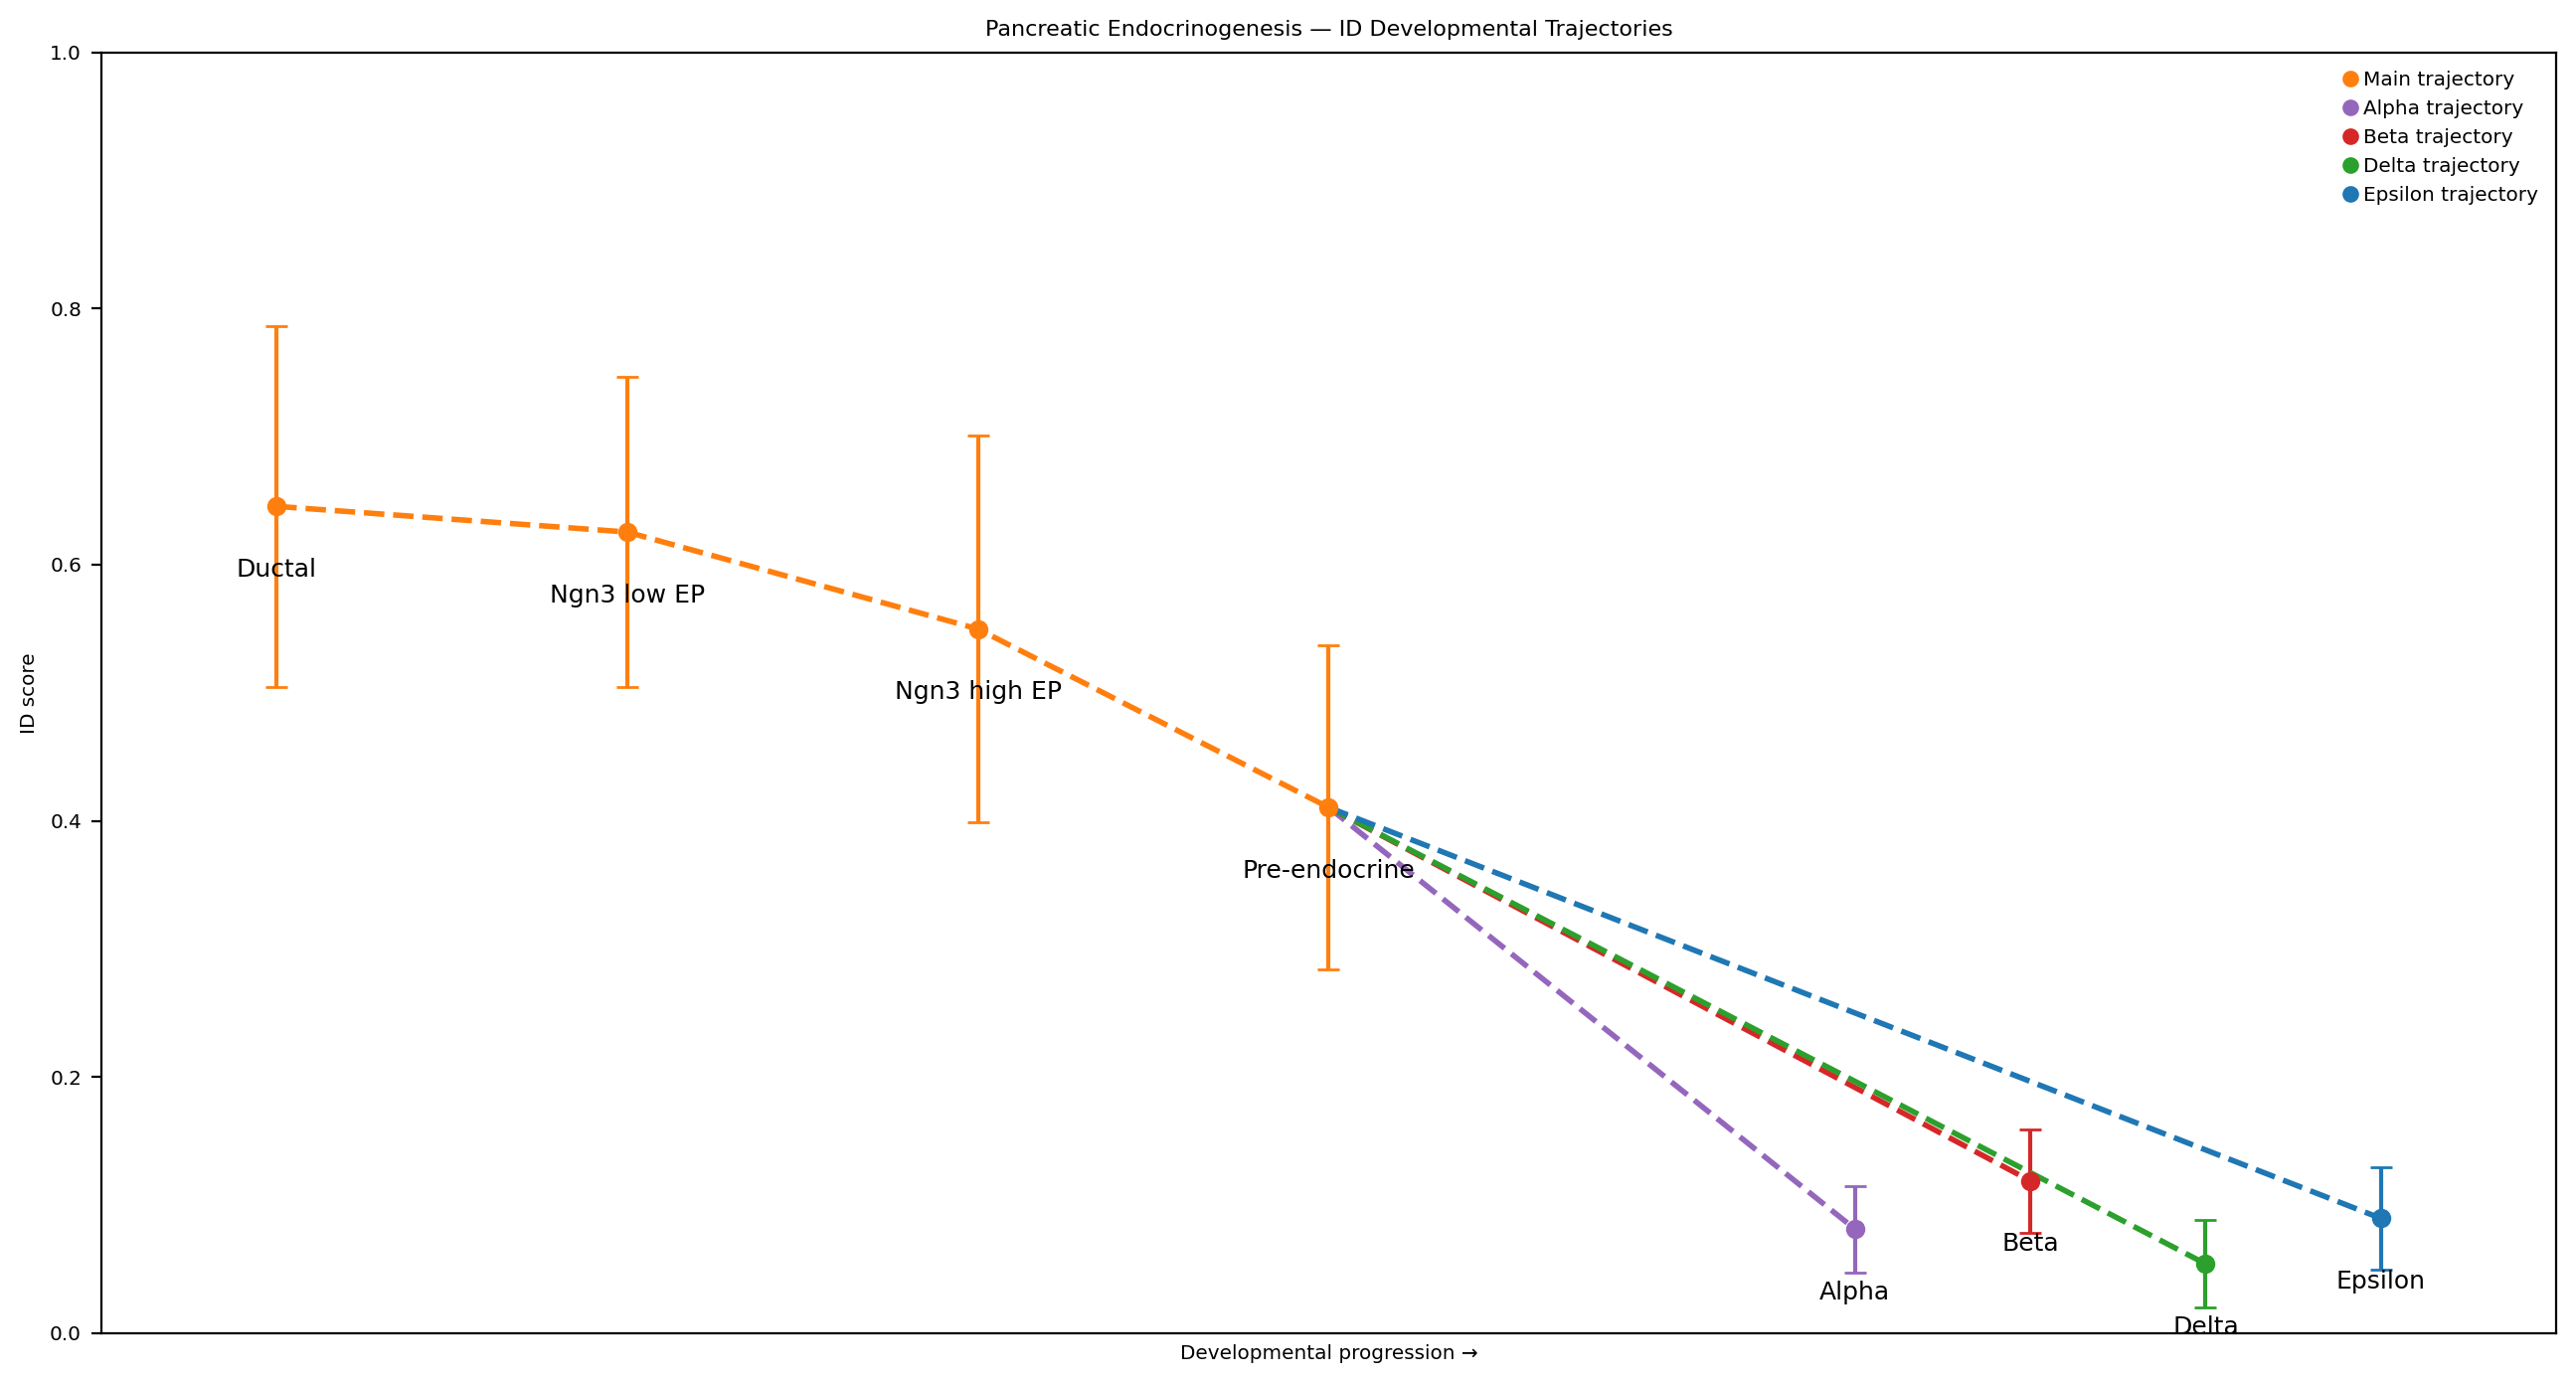

In [9]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Alpha",
    "Beta",
    "Delta",
    "Epsilon"
]


# ============================================================
# MAKE LOOKUP DICTIONARIES FROM id_summary
# ============================================================

id_mean = (
    id_summary
    .set_index("clusters")["ID"]
    .to_dict()
)

id_sd = (
    id_summary
    .set_index("clusters")["SD"]
    .to_dict()
)


# ============================================================
# X POSITIONS
#
# These are ONLY for the developmental layout.
# Y = actual ID score.
# ============================================================

x = {

    # Main trajectory
    "Ductal":        0.0,
    "Ngn3 low EP":   1.0,
    "Ngn3 high EP":  2.0,
    "Pre-endocrine": 3.0,

    # Terminal branches
    "Alpha":         4.5,
    "Beta":          5.0,
    "Delta":         5.5,
    "Epsilon":       6.0,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":    "tab:orange",
    "alpha":   "tab:purple",
    "beta":    "tab:red",
    "delta":   "tab:green",
    "epsilon": "tab:blue"
}


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# HELPER: PLOT ONE ID POINT + ERROR BAR
# ============================================================

def plot_id_point(name, color):

    if name not in id_mean:
        return

    ax.errorbar(
        x[name],
        id_mean[name],
        yerr=id_sd[name],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        markersize=6,
        linewidth=1.5
    )


# ============================================================
# MAIN TRAJECTORY
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
#
# Pre-endocrine is part of the main trajectory and therefore
# gets the main/orange color.
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]


# Main trajectory line

ax.plot(
    [x[name] for name in main_path],
    [id_mean[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Main trajectory"
)


# Main trajectory points + error bars

for name in main_path:

    plot_id_point(
        name,
        colors["main"]
    )


# ============================================================
# ALPHA BRANCH
#
# Pre-endocrine → Alpha
# ============================================================

alpha_branch = [
    "Alpha"
]

alpha_line = [
    "Pre-endocrine",
    "Alpha"
]


ax.plot(
    [x[name] for name in alpha_line],
    [id_mean[name] for name in alpha_line],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory"
)


for name in alpha_branch:

    plot_id_point(
        name,
        colors["alpha"]
    )


# ============================================================
# BETA BRANCH
#
# Pre-endocrine → Beta
# ============================================================

beta_branch = [
    "Beta"
]

beta_line = [
    "Pre-endocrine",
    "Beta"
]


ax.plot(
    [x[name] for name in beta_line],
    [id_mean[name] for name in beta_line],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory"
)


for name in beta_branch:

    plot_id_point(
        name,
        colors["beta"]
    )


# ============================================================
# DELTA BRANCH
#
# Pre-endocrine → Delta
# ============================================================

delta_branch = [
    "Delta"
]

delta_line = [
    "Pre-endocrine",
    "Delta"
]


ax.plot(
    [x[name] for name in delta_line],
    [id_mean[name] for name in delta_line],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory"
)


for name in delta_branch:

    plot_id_point(
        name,
        colors["delta"]
    )


# ============================================================
# EPSILON BRANCH
#
# Pre-endocrine → Epsilon
# ============================================================

epsilon_branch = [
    "Epsilon"
]

epsilon_line = [
    "Pre-endocrine",
    "Epsilon"
]


ax.plot(
    [x[name] for name in epsilon_line],
    [id_mean[name] for name in epsilon_line],
    "o--",
    color=colors["epsilon"],
    linewidth=2,
    markersize=5,
    label="Epsilon trajectory"
)


for name in epsilon_branch:

    plot_id_point(
        name,
        colors["epsilon"]
    )


# ============================================================
# LABELS
# ============================================================

label_offset = {

    "Ductal":        -0.04,
    "Ngn3 low EP":   -0.04,
    "Ngn3 high EP":  -0.04,
    "Pre-endocrine": -0.04,

    "Alpha":         -0.04,
    "Beta":          -0.04,
    "Delta":         -0.04,
    "Epsilon":       -0.04,
}


for name in cluster:

    if name not in id_mean:
        continue

    ax.text(
        x[name],
        id_mean[name] + label_offset[name],
        name,
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 6.5)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("ID score")

# ID is normalized between 0 and 1

ax.set_ylim(0, 1)

ax.set_title(
    "Pancreatic Endocrinogenesis — ID Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()

plt.show()

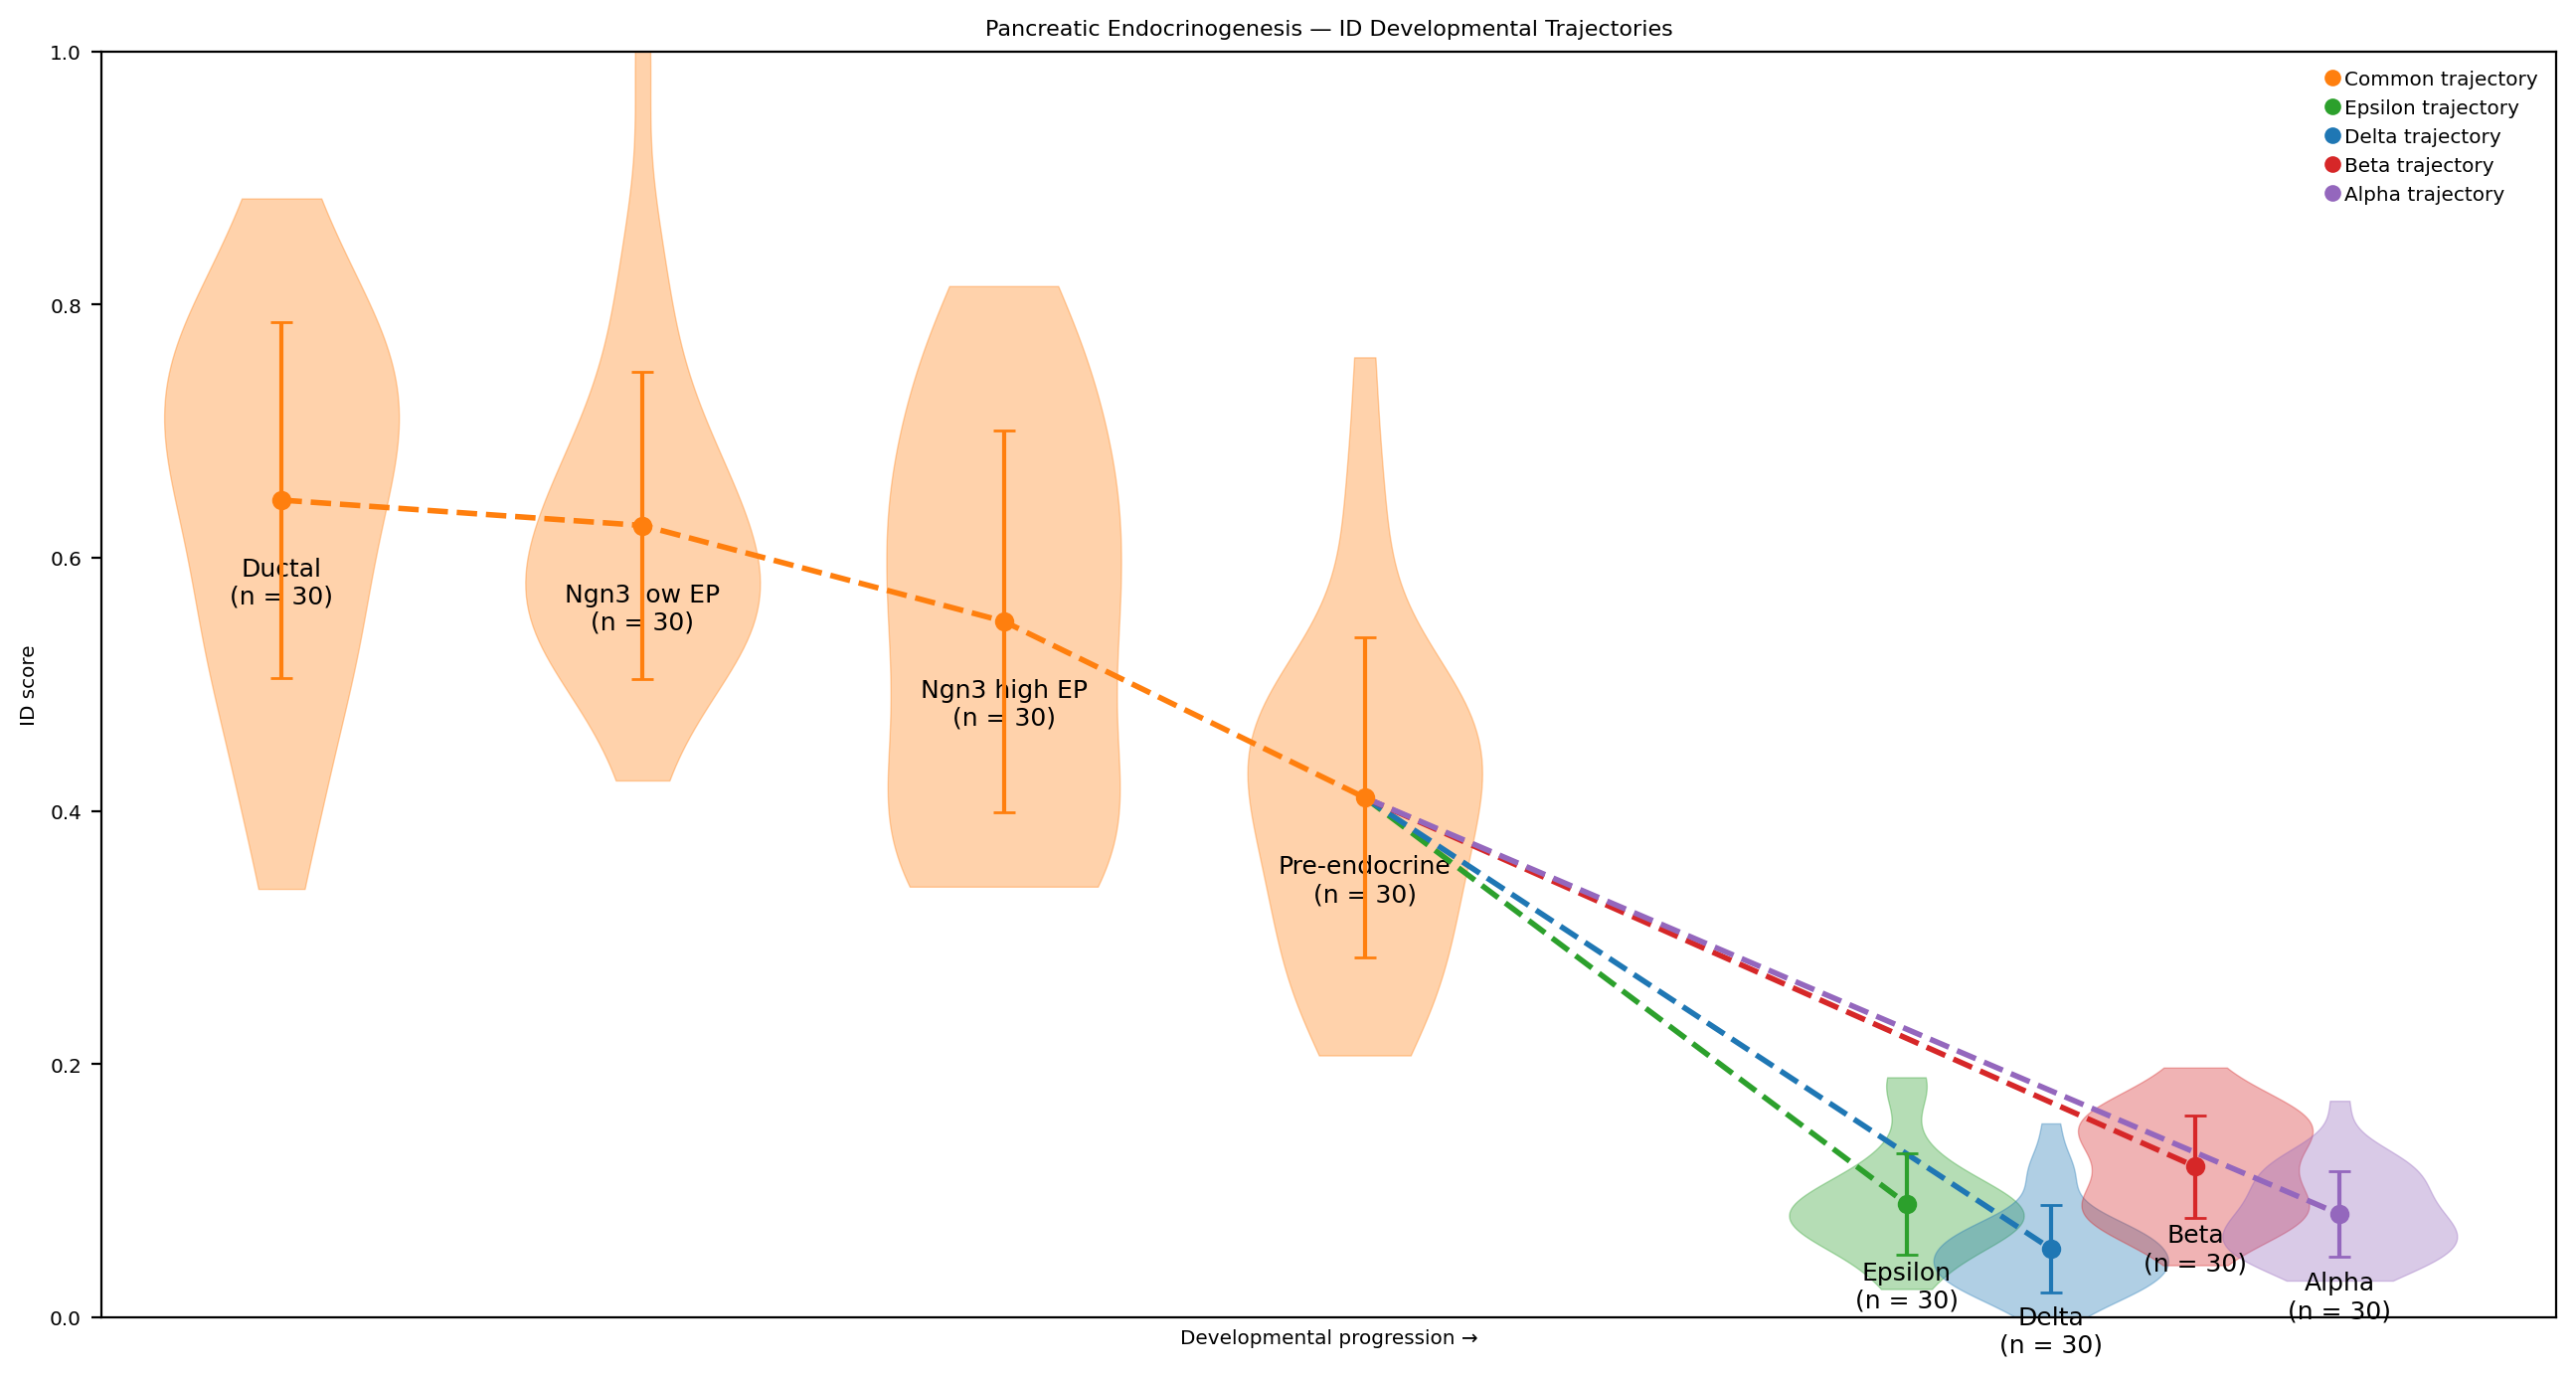

In [10]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]


# ============================================================
# ID MEAN + SD
# ============================================================

id_mean = (
    id_summary
    .set_index("clusters")["ID"]
    .to_dict()
)

id_sd = (
    id_summary
    .set_index("clusters")["SD"]
    .to_dict()
)


# ============================================================
# CELL-LEVEL ID DISTRIBUTIONS
#
# id_results:
#   rows    = individual ID calculations
#   columns = clusters
# ============================================================

id_groups = {
    name: id_results[name].dropna().values
    for name in cluster
    if name in id_results.columns
}


# ============================================================
# NUMBER OF CELLS / ID VALUES
# ============================================================

cell_counts = {
    name: len(id_groups[name])
    for name in id_groups
}


# ============================================================
# X POSITIONS
#
# These are ONLY used to create the developmental layout.
#
# Common trajectory:
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
#
# Then four branches:
#
#                          → Epsilon
#                          → Delta
# Pre-endocrine ──────────→ Beta
#                          → Alpha
# ============================================================

x = {

    # Common trajectory
    "Ductal":          0.0,
    "Ngn3 low EP":     1.0,
    "Ngn3 high EP":    2.0,
    "Pre-endocrine":   3.0,

    # Epsilon branch
    "Epsilon":         4.5,

    # Delta branch
    "Delta":           4.9,

    # Beta branch
    "Beta":            5.3,

    # Alpha branch
    "Alpha":           5.7,
}


# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":    "tab:orange",
    "epsilon": "tab:green",
    "delta":   "tab:blue",
    "beta":    "tab:red",
    "alpha":   "tab:purple"
}


# ============================================================
# ASSIGN EACH CLUSTER TO A TRAJECTORY
# ============================================================

trajectory = {

    # Common developmental trajectory
    "Ductal":        "main",
    "Ngn3 low EP":   "main",
    "Ngn3 high EP":  "main",
    "Pre-endocrine": "main",

    # Terminal branches
    "Epsilon":       "epsilon",
    "Delta":         "delta",
    "Beta":          "beta",
    "Alpha":         "alpha",
}


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in id_groups:
        continue

    values = id_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Color violin according to developmental trajectory
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# HELPER: POINT + ERROR BAR
# ============================================================

def plot_id_point(name, color):

    if name not in id_mean:
        return

    ax.errorbar(
        x[name],
        id_mean[name],
        yerr=id_sd[name],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        markersize=6,
        linewidth=1.5,
        zorder=5
    )


# ============================================================
# COMMON / MAIN TRAJECTORY
#
# Ductal → Ngn3 low EP → Ngn3 high EP → Pre-endocrine
# ============================================================

main_path = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]

ax.plot(
    [x[name] for name in main_path],
    [id_mean[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Common trajectory",
    zorder=4
)

for name in main_path:
    plot_id_point(name, colors["main"])


# ============================================================
# EPSILON BRANCH
#
# Pre-endocrine → Epsilon
#
# Pre-endocrine itself is NOT redrawn.
# ============================================================

epsilon_line = [
    "Pre-endocrine",
    "Epsilon"
]

ax.plot(
    [x[name] for name in epsilon_line],
    [id_mean[name] for name in epsilon_line],
    "o--",
    color=colors["epsilon"],
    linewidth=2,
    markersize=5,
    label="Epsilon trajectory",
    zorder=4
)

plot_id_point("Epsilon", colors["epsilon"])


# ============================================================
# DELTA BRANCH
#
# Pre-endocrine → Delta
# ============================================================

delta_line = [
    "Pre-endocrine",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_line],
    [id_mean[name] for name in delta_line],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory",
    zorder=4
)

plot_id_point("Delta", colors["delta"])


# ============================================================
# BETA BRANCH
#
# Pre-endocrine → Beta
# ============================================================

beta_line = [
    "Pre-endocrine",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_line],
    [id_mean[name] for name in beta_line],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory",
    zorder=4
)

plot_id_point("Beta", colors["beta"])


# ============================================================
# ALPHA BRANCH
#
# Pre-endocrine → Alpha
# ============================================================

alpha_line = [
    "Pre-endocrine",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_line],
    [id_mean[name] for name in alpha_line],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory",
    zorder=4
)

plot_id_point("Alpha", colors["alpha"])


# ============================================================
# LABELS
# ============================================================

for name in cluster:

    if name not in id_mean:
        continue

    ax.text(
        x[name],
        id_mean[name] - 0.045,
        f"{name}\n(n = {cell_counts.get(name, 0)})",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 6.3)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("ID score")

ax.set_ylim(0, 1)

ax.set_title(
    "Pancreatic Endocrinogenesis — ID Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

Terminal cells: 120

FIRST 2 / 3 / 4 VS TERMINAL


,Comparison,t_stat,p_value,n_early,n_terminal,p_adj
0,First 2 vs Terminal,31.708540,1.620290e-41,60,120,1.620290e-41
1,First 3 vs Terminal,33.461544,1.259923e-56,90,120,1.889885e-56
2,First 4 vs Terminal,30.695709,5.365616e-63,120,120,1.609685e-62


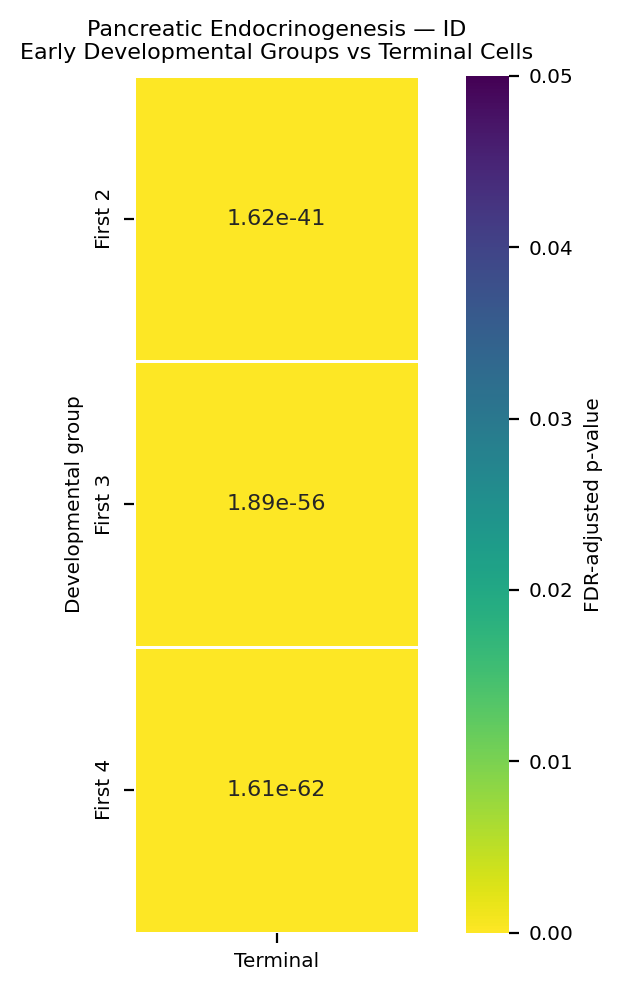


INDIVIDUAL EARLY POPULATIONS VS TERMINAL


,Comparison,t_stat,p_value,n_early,n_terminal,p_adj
0,Ductal vs Terminal,21.505678,6.034523e-20,30,120,1.206905e-19
1,Ngn3 low EP vs Terminal,23.995541,1.549953e-21,30,120,6.199813e-21
2,Ngn3 high EP vs Terminal,16.658699,8.942835e-17,30,120,1.192378e-16
3,Pre-endocrine vs Terminal,13.832843,9.694293e-15,30,120,9.694293e-15


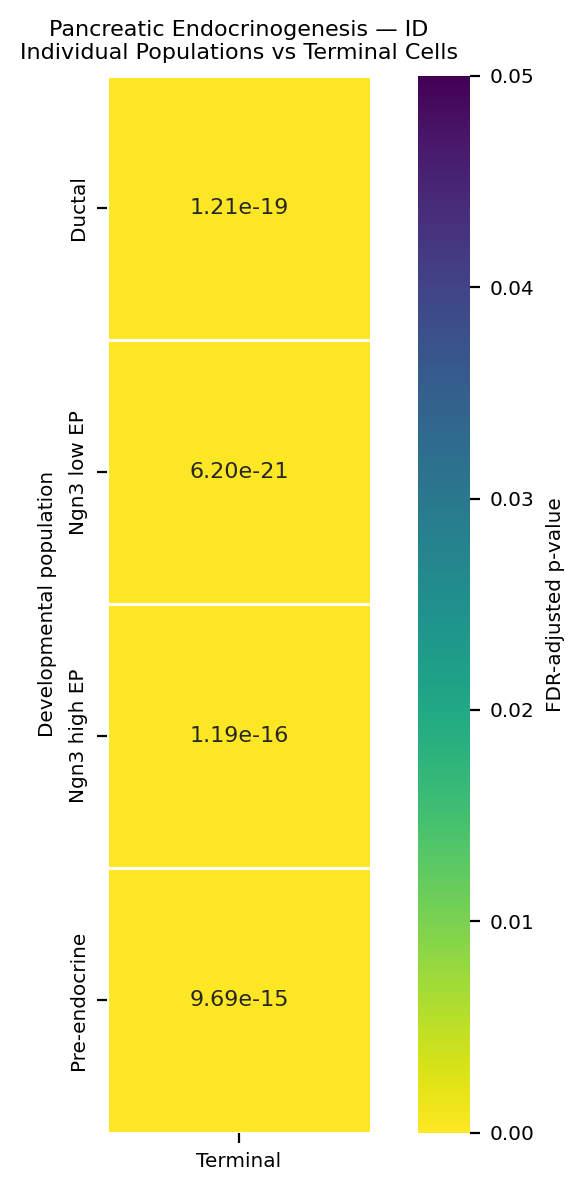

In [11]:
# ============================================================
# ID STATISTICAL ANALYSIS
# EARLY DEVELOPMENTAL GROUPS VS TERMINAL CELLS
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEVELOPMENTAL GROUPS
# ============================================================

terminal_clusters = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]

first2_clusters = [
    "Ductal",
    "Ngn3 low EP"
]

first3_clusters = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP"
]

first4_clusters = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine"
]


# ============================================================
# HELPER: COMBINE CELL-LEVEL ID VALUES
# ============================================================

def combine_id(clusters):

    arrays = []

    for name in clusters:

        if name in id_results.columns:

            values = (
                pd.to_numeric(
                    id_results[name],
                    errors="coerce"
                )
                .dropna()
                .values
            )

            if len(values) > 0:
                arrays.append(values)

    if len(arrays) == 0:
        return np.array([])

    return np.concatenate(arrays)


# ============================================================
# TERMINAL GROUP
# ============================================================

terminal_values = combine_id(terminal_clusters)


print("Terminal cells:", len(terminal_values))


# ============================================================
# ============================================================
# PLOT 1
# FIRST 2 / FIRST 3 / FIRST 4 VS TERMINAL
# ============================================================
# ============================================================

group_definitions = {
    "First 2": first2_clusters,
    "First 3": first3_clusters,
    "First 4": first4_clusters
}


results_1 = []


for label, clusters in group_definitions.items():

    early_values = combine_id(clusters)

    statistic, p_value = ttest_ind(
        early_values,
        terminal_values,
        equal_var=False
    )

    results_1.append({
        "Comparison": f"{label} vs Terminal",
        "t_stat": statistic,
        "p_value": p_value,
        "n_early": len(early_values),
        "n_terminal": len(terminal_values)
    })


results_1 = pd.DataFrame(results_1)


# ============================================================
# FDR CORRECTION
# ============================================================

results_1["p_adj"] = multipletests(
    results_1["p_value"],
    method="fdr_bh"
)[1]


print("\n==========================================")
print("FIRST 2 / 3 / 4 VS TERMINAL")
print("==========================================")

display(results_1)


# ============================================================
# CREATE P-ADJ MATRIX
# ============================================================

heatmap_1 = pd.DataFrame(
    np.nan,
    index=[
        "First 2",
        "First 3",
        "First 4"
    ],
    columns=["Terminal"]
)


for _, row in results_1.iterrows():

    label = row["Comparison"].split(" vs ")[0]

    heatmap_1.loc[label, "Terminal"] = row["p_adj"]


# ============================================================
# HEATMAP
# ============================================================

plt.figure(figsize=(5, 5))

sns.heatmap(
    heatmap_1,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "Pancreatic Endocrinogenesis — ID\n"
    "Early Developmental Groups vs Terminal Cells"
)

plt.xlabel("")
plt.ylabel("Developmental group")

plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# PLOT 2
# EACH INDIVIDUAL EARLY POPULATION VS TERMINAL
# ============================================================
# ============================================================

individual_groups = {
    "Ductal": ["Ductal"],
    "Ngn3 low EP": ["Ngn3 low EP"],
    "Ngn3 high EP": ["Ngn3 high EP"],
    "Pre-endocrine": ["Pre-endocrine"]
}


results_2 = []


for label, clusters in individual_groups.items():

    early_values = combine_id(clusters)

    statistic, p_value = ttest_ind(
        early_values,
        terminal_values,
        equal_var=False
    )

    results_2.append({
        "Comparison": f"{label} vs Terminal",
        "t_stat": statistic,
        "p_value": p_value,
        "n_early": len(early_values),
        "n_terminal": len(terminal_values)
    })


results_2 = pd.DataFrame(results_2)


# ============================================================
# FDR CORRECTION
# ============================================================

results_2["p_adj"] = multipletests(
    results_2["p_value"],
    method="fdr_bh"
)[1]


print("\n==========================================")
print("INDIVIDUAL EARLY POPULATIONS VS TERMINAL")
print("==========================================")

display(results_2)


# ============================================================
# CREATE P-ADJ MATRIX
# ============================================================

heatmap_2 = pd.DataFrame(
    np.nan,
    index=[
        "Ductal",
        "Ngn3 low EP",
        "Ngn3 high EP",
        "Pre-endocrine"
    ],
    columns=["Terminal"]
)


for _, row in results_2.iterrows():

    label = row["Comparison"].split(" vs ")[0]

    heatmap_2.loc[label, "Terminal"] = row["p_adj"]


# ============================================================
# HEATMAP
# ============================================================

plt.figure(figsize=(5, 6))

sns.heatmap(
    heatmap_2,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "Pancreatic Endocrinogenesis — ID\n"
    "Individual Populations vs Terminal Cells"
)

plt.xlabel("")
plt.ylabel("Developmental population")

plt.tight_layout()
plt.show()